### **Title : Mental Health in Tech: A Sociodemographic Analysis**

#### **Introduction**

- This project performs an **Exploratory Data Analysis (EDA)** on the *Mental Health in Tech Industry* dataset.
- The objective is to explore **trends, relationships, and patterns** among the sociodemographic characteristics of survey respondents.
- The project includes **data cleaning, descriptive statistics, grouped analysis, and data visualisation** using Python and Pandas to gain further insights into the dataset.



##### **Dataset Overview**

- The dataset contains **4,218 survey respondents** and their responses to **10 questions** covering different sociodemographic factors, such as **age, race, occupation, and employment location**.
- **SQL** was used to combine and manipulate data from three tables: **Answer, Question, and Survey**, producing the final dataset for analysis.
- The analysis uses **Pandas, NumPy, Seaborn, and Matplotlib** to explore the data, identify patterns, and compare different sociodemographic characteristics.

##### **Sample and Sociodemographic Features**

- The respondents were analysed based on factors including **age, gender, race, employment status, occupation, country of residence, and work mode**.
- Some variables contained a significant number of **missing values**, which may affect the interpretation of certain demographic patterns.
- The sample also showed **uneven representation across countries and demographic groups**, suggesting that it may not fully represent the wider working population.

##### **Potential Sampling Bias**

- There is evidence of **potential sampling bias**, as some countries and demographic groups are more strongly represented than others.
- Therefore, the findings should be interpreted as reflecting the **survey sample rather than the entire population of workers**.

### **Data Preparation**

##### **Import Libary and Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

palette = sns.color_palette("Set2")
sns.set_palette(palette)

In [2]:
survey = pd.read_csv("Mental_health_dataset.csv")
survey.head()

,UserID,SurveyID,Age,Gender,Country_of_Residence,Employment_country,self_employed,company_size,tech_company,tech_role,Suspected_conditions,Diagonsed_conditions,Diagonsed
0,4218,2019,24,Female,United States of America,United States of America,0,More than 1000,1,1.0,NaN,NaN,Yes
1,4217,2019,30,female,India,India,0,More than 1000,1,1.0,NaN,NaN,-1
2,4216,2019,50,Male,India,India,1,-1,-1,-1.0,NaN,NaN,-1
3,4215,2019,48,Male,United States of America,United States of America,1,-1,-1,-1.0,NaN,NaN,-1
4,4214,2019,27,male,India,India,0,More than 1000,0,1.0,NaN,NaN,-1


### 2. **Data Check**

#### 2.1. **Structure Check**

In [3]:
survey.info()

<class 'pandas.DataFrame'>
RangeIndex: 4218 entries, 0 to 4217
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   UserID                4218 non-null   int64  
 1   SurveyID              4218 non-null   int64  
 2   Age                   4218 non-null   int64  
 3   Gender                4215 non-null   str    
 4   Country_of_Residence  4218 non-null   str    
 5   Employment_country    2958 non-null   str    
 6   self_employed         4218 non-null   int64  
 7   company_size          4218 non-null   str    
 8   tech_company          4218 non-null   int64  
 9   tech_role             2958 non-null   float64
 10  Suspected_conditions  1433 non-null   str    
 11  Diagonsed_conditions  1433 non-null   str    
 12  Diagonsed             2958 non-null   str    
dtypes: float64(1), int64(5), str(7)
memory usage: 428.5 KB


#### 2.2 **Duplicates**

In [4]:
survey.duplicated().value_counts()

False    4218
Name: count, dtype: int64

#### 2.3 **Null Values**

In [5]:
null_values = (survey.isnull().sum()/len(survey))*100
print(null_values)

UserID                   0.000000
SurveyID                 0.000000
Age                      0.000000
Gender                   0.071124
Country_of_Residence     0.000000
Employment_country      29.871977
self_employed            0.000000
company_size             0.000000
tech_company             0.000000
tech_role               29.871977
Suspected_conditions    66.026553
Diagonsed_conditions    66.026553
Diagonsed               29.871977
dtype: float64


In [6]:
str_columns_to_clean = ["Diagonsed_conditions", "Suspected_conditions","Country_of_Residence", "Employment_country" , "Gender"]
survey[str_columns_to_clean] = survey[str_columns_to_clean] .fillna("unknown")

#fill It columns 
int_columns_to_clean = ['tech_role' ,'Diagonsed']
survey[int_columns_to_clean] = survey[int_columns_to_clean] .fillna("-1")

In [7]:
null_values = (survey.isnull().sum()/len(survey))*100
print(null_values)

UserID                  0.0
SurveyID                0.0
Age                     0.0
Gender                  0.0
Country_of_Residence    0.0
Employment_country      0.0
self_employed           0.0
company_size            0.0
tech_company            0.0
tech_role               0.0
Suspected_conditions    0.0
Diagonsed_conditions    0.0
Diagonsed               0.0
dtype: float64


#### 2.4 **Outliers**

- Outliers were identified to detect **unusual or extreme values** within the dataset.
- This was done to ensure that extreme observations could be **reviewed and appropriately handled** before further analysis.

In [8]:
survey.describe()

,UserID,SurveyID,Age,self_employed,tech_company
count,4218.000000,4218.000000,4218.000000,4218.000000,4218.000000
mean,2109.500000,2016.029872,33.915363,0.149834,0.565197
std,1217.776047,1.587555,10.478054,0.368715,0.696305
min,1.000000,2014.000000,-29.000000,-1.000000,-1.000000
25%,1055.250000,2014.000000,28.000000,0.000000,0.000000
50%,2109.500000,2016.000000,33.000000,0.000000,1.000000
75%,3163.750000,2017.000000,38.000000,0.000000,1.000000
max,4218.000000,2019.000000,329.000000,1.000000,1.000000


**Age** *column is the only confirmed Numerical column as others (userid , surveyid e.t.c ) have unrelated to this categories.*
*This column will be processed for outliers and data cleaning will be introduced to this column.*
1. *Min is -29 (not possible)*
2. *Max is 329 (not possible)*

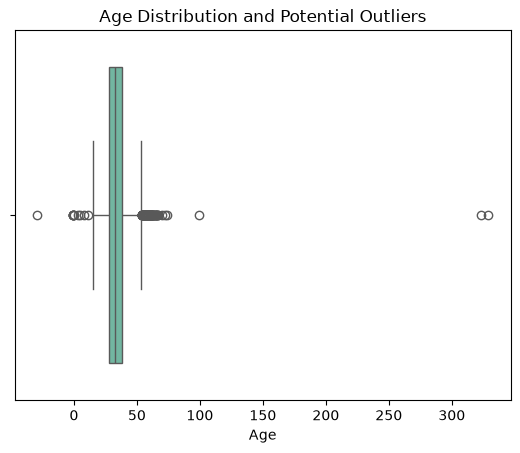

In [9]:
survey["Age"] = pd.to_numeric(survey["Age"], errors="coerce")
sns.boxplot (x=survey["Age"])
plt.title("Age Distribution and Potential Outliers")
plt.show()

**The average working Age is between 18 and 70 following the government retirement . However in most cases people manage companies and businesses untill the age of 100, so it is viable to say the min should be 18 and the max 100 .**

#### 2.5 **Correlation**

##### Is age associated with whether respondents report a mental health condition?

<function matplotlib.pyplot.show(close=None, block=None)>

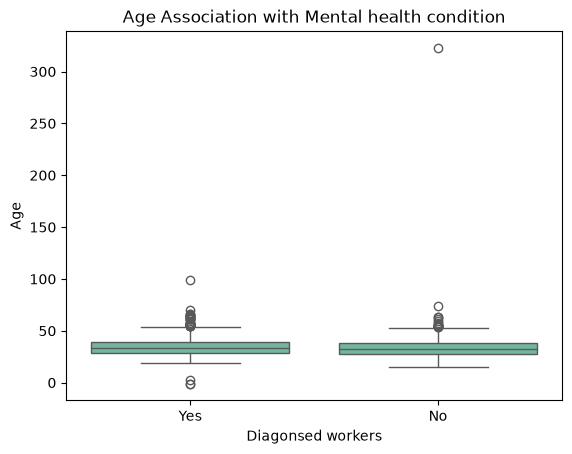

In [10]:
Corr = survey.loc[survey[ "Diagonsed"].astype(str).str.strip()!= "-1"]
sns.boxplot ( data = Corr , x = "Diagonsed" , y = "Age" )
plt.title ("Age Association with Mental health condition"),
plt.xlabel ("Diagonsed workers")
plt.ylabel ("Age")
plt.show

In [11]:
survey["Diagonsed"] = survey["Diagonsed"].replace({"Yes": "1" , "No":"0"})
survey["Diagonsed"].astype(int)

#r_val, p_val = stats.pearsonr(survey['Age'], survey['Diagonsed'])
clean_data = survey[survey['Diagonsed'] != -1]
r_val = clean_data['Age'].corr(clean_data['Diagonsed'])
print(f'r_val:{r_val:.4f}')

r_val:0.0517


##### Pearson correlation (r) = 0.0726, indicating a very weak positive association between age and diagnosis status.

### 3. **Data Cleaning**

##### 3.1 **Data Cleaning and Treatment of -1 Values**
- According to OSMI (https://www.researchgate.net/publication/366737538_Predicting_mental_illness_at_workplace_using_machine_learning), -1 is not a universal answer option printed on the questionnaire. It is a numerical code used by researchers to represent certain valid answers, and its meaning depends on the answer choices for the particular question.
- Therefore, the -1 responses were excluded from the relevant analyses where they did not represent meaningful values for the analysis being performed.
Data Type Cleaning
Some columns were cleaned and converted to appropriate data types to ensure they could be used correctly in the analysis. These included:
1. Age
2. Gender
3. Diagnosed Conditions
4. Suspected Conditions
5. Company Size
6. Country of Residence
7. Employment Country


Response coding: For Questions 9 (Tech companies) and 13 (Tech Roles) and 5 (Self employed), 
1 represents Yes and 0 represents No. 
The original numerical values have been retained.

In [12]:
str_columns_to_clean = ["Diagonsed_conditions", "Suspected_conditions","Country_of_Residence", "Employment_country" , "Gender"]
survey[str_columns_to_clean] = survey[str_columns_to_clean].replace(r"^\s*-1\s*$", "Unknown" , regex=True)

In [13]:
# cleaning null columns with integers - to match maybe values
int_columns = ["tech_role","Diagonsed"]
survey[int_columns] = survey[int_columns].fillna('-1')

##### 3.2 **Cleaning and Categorising the Gender Column**

- The Gender column was cleaned and categorised to **standardise responses and identify Null values**.
- This was necessary to ensure **consistent and accurate analysis** of gender-related patterns.

In [14]:
 
gender_map = {
    "Male": ["Male", "male", "MALE", "Male-ish",
        "Guy (-ish) ^_^", "Cishet male",
        "Masculine", "masculino", "SWM",
        "something kinda male?",
        "ostensibly male, unsure what that really means",
        "Ostensibly Male",
        "male leaning androgynous",
        "male 9:1 female, roughly",
        "Male (trans, FtM)",
        "Trans man",
        "Demiguy"
        ],

    "Female": ["Female", "female", "Female (trans)",
        "Trans woman", "trans woman",
        "Transgender woman", "Trans female",
        "Trans-female", "mtf", "Transitioned, M2F",
        "Female assigned at birth",
        "Female-ish", "Female-identified",
        "Woman-identified", "femmina",
        "genderqueer woman",
        "gender non-conforming woman"
        ],

    "Non-binary": ["Nonbinary",
        "nonbinary",
        "non-binary",
        "Non-binary",
        "Non binary",
        "non binary",
        "Enby",
        "NB",
        "Genderqueer/non-binary",
        "Female/gender non-binary.",
        "Trans non-binary/genderfluid",
        "Non-binary and gender fluid"
        ],
    "Gender diverse" : ["Genderqueer",
        "genderqueer",
        "Agender",
        "agender",
        "Genderfluid",
        "genderfluid",
        "Genderfluid (born female)",
        "Genderqueer demigirl",
        "Genderflux demi-girl",
        "Bigender",
        "Androgyne",
        "Androgynous",
        "Neuter",
        "Fluid",
        "fluid",
        "Demiguy",
        "Transfeminine",
        "Other/Transfeminine",
        "Agender/genderfluid",
        "nb masculine",
        "Male/genderqueer",
        "male/androgynous",
        "Nonbinary/femme",
        "Trans non-binary/genderfluid",
        "uhhhhhhh fem genderqueer?",
        "genderqueer woman",
        "Trans non-binary/genderfluid",
        "queer",
        "Queer",
        "Questioning",
        "sometimes"
        ],

    "Other / Self-described": [
        "Other", "All", "Human", "human",
        "Unicorn", "I am a Wookie",
        "God King of the Valajar",
        "Contextual", "A little about you",
        "I have a penis", "none of your business",
        "female-bodied; no feelings about gender",
        "Male (or female, or both)",
        "male 9:1 female, roughly",
        "uhhhhhhhh fem genderqueer?",
        "Male/genderqueer",
        "A little about you"
        ],

    "Unknown": [
        "-1", "Nah", "none", "p", "rr",
        "43", "\\-", "fm"
    ]
    
}


gender_lookup = {}
for category, responses in gender_map.items():
    for response in responses:
        gender_lookup[response] = category
survey["Gender_Category"] = survey["Gender"].map(gender_lookup)
survey = survey.dropna(subset=["Gender_Category"])
survey = survey.drop(columns=["Gender"])
print(survey["Gender_Category"].value_counts(dropna=False))



Gender_Category
Male                      3057
Female                    1040
Gender diverse              37
Non-binary                  27
Other / Self-described      16
Unknown                      7
Name: count, dtype: int64


In [15]:

survey = survey.rename(columns = {"Gender_Category": "Gender"})

##### 3.3 **Cleaning and Categorising the Country of Residence Column**

- **“United States”** and **“United States of America”** were standardised into a single **“United States”** category.
- This was done to **avoid duplicate categories and ensure accurate country-level analysis**.

In [16]:

survey["Country_of_Residence"].replace({"United States": "United States of America"})


0       United States of America
1                          India
2                          India
3       United States of America
4                          India
                  ...           
4213    United States of America
4214              United Kingdom
4215                      Canada
4216    United States of America
4217    United States of America
Name: Country_of_Residence, Length: 4184, dtype: str

In [17]:
survey.describe()

,UserID,SurveyID,Age,self_employed,tech_company
count,4184.000000,4184.000000,4184.000000,4184.000000,4184.000000
mean,2101.029159,2016.018881,33.938337,0.148662,0.567639
std,1216.690841,1.585820,10.468788,0.367693,0.694030
min,1.000000,2014.000000,-29.000000,-1.000000,-1.000000
25%,1047.750000,2014.000000,28.000000,0.000000,0.000000
50%,2096.500000,2016.000000,33.000000,0.000000,1.000000
75%,3152.250000,2017.000000,38.000000,0.000000,1.000000
max,4218.000000,2019.000000,329.000000,1.000000,1.000000


In [18]:
survey.loc[
    (survey["Age"] < 18) | (survey["Age"] > 100),
    ["UserID", "SurveyID", "Age"]]

,UserID,SurveyID,Age
237,3981,2019,0
2149,2069,2016,15
2301,1917,2016,3
2393,1825,2016,323
2864,1354,2016,17
3090,1128,2014,-1
3127,1091,2014,11
3228,990,2014,8
3483,735,2014,5
3502,716,2014,-1


In [19]:
survey.drop(
    survey.loc[
        (survey["Age"] < 18) | (survey["Age"] > 100)
    ].index,
    inplace=True)


### **Explorative Data Analysis**

##### This section higlights and showcases various relationships and data driven conclusion between the selected criteria. Questions are solved and answered to show how each of these criteria(column) affect Mental health. 

####  **Age total distribution among responders?**

Text(0, 0.5, 'Number of Responders')

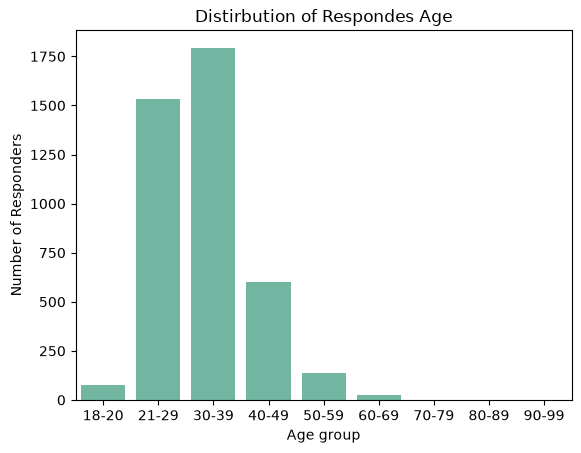

In [20]:
# creating bins to group the age of respondent 
survey['age_group']= pd.cut(survey.Age, bins = [18,21,30,40,50,60,70,80,90,100], labels = ["18-20","21-29","30-39","40-49","50-59","60-69","70-79","80-89","90-99"])
count_age_of_responders = (survey['age_group'].value_counts())
Number_of_Responders = count_age_of_responders.to_frame()
sns.barplot(data = Number_of_Responders ,x = 'age_group', y = 'count')
plt.title ('Distirbution of Respondes Age')
plt.xlabel('Age group')
plt.ylabel('Number of Responders')


##### *the Age_group '30-39' has the highest number of reponders .*

#### **A Map showing the Diagonised Employees across the Globe**

In [21]:

Residence = (
    survey.loc[
        pd.to_numeric(survey["Diagonsed"], errors="coerce") == 1,
        "Country_of_Residence"
    ]
    .value_counts()
    .sort_values(ascending=False)
)

world = gpd.read_file("ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp")

world["ADMIN"] = world["ADMIN"].str.lower()
survey["Country_of_Residence"] = survey["Country_of_Residence"].astype(str).str.strip().str.lower()

country_counts = (
    survey["Country_of_Residence"]
    .value_counts()
    .rename_axis("ADMIN")
    .rename("responders_number")
    .reset_index()
)
merged_country = world[["ADMIN", "geometry"]].merge(country_counts, on="ADMIN", how="left")
merged_country = merged_country[merged_country["responders_number"].notna()]


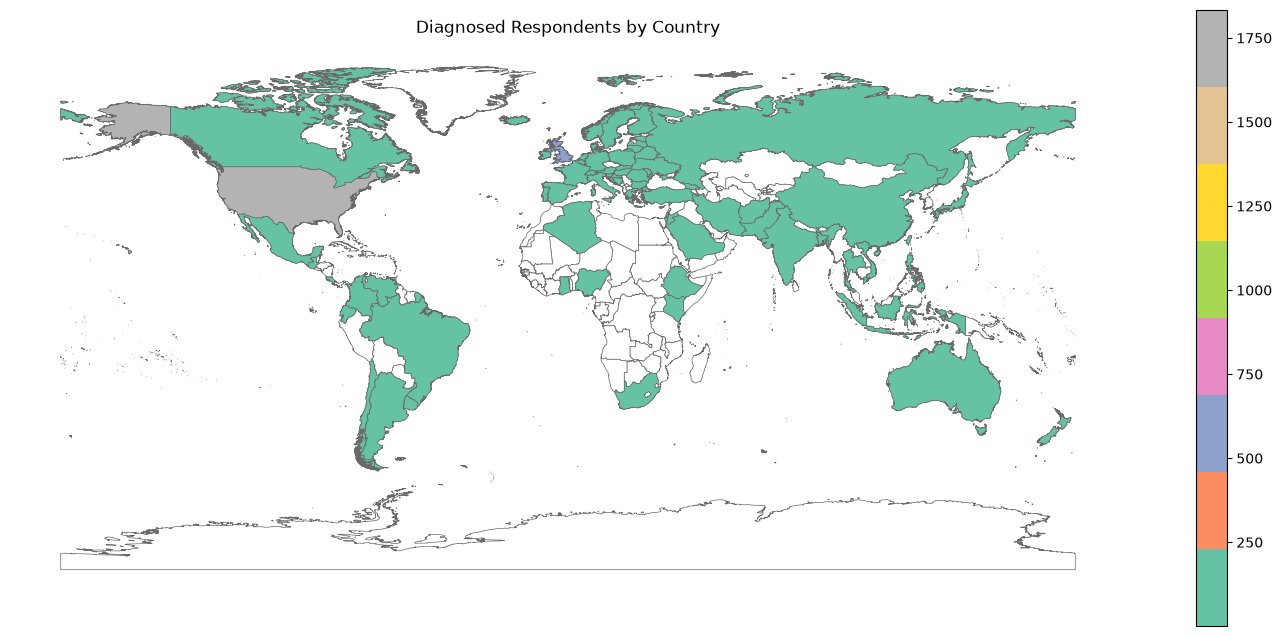

In [ ]:
world = gpd.read_file(
    "ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp"
)
merged = world.set_index("ADMIN").join(survey.set_index("Country_of_Residence"))
fig, ax = plt.subplots(figsize=(18, 8))
world.plot(
    ax=ax,
    color="white",
    edgecolor="dimgray",
    linewidth=0.5
)
merged_country_plot = merged_country.plot(
    ax=ax,
    column="responders_number",
    cmap="Set2",
    edgecolor="dimgray",
    linewidth=0.5,
    legend=True,
    figsize=(18, 8)
)
ax.set_title("Diagnosed Respondents by Country")
ax.set_axis_off()

plt.show()

##### *The United states of America has the highest number of Diagnoses in tech roles*

#### **How does company size relate to the distribution of mental health conditions?**

In [ ]:
survey['Diagonsed_conditions']. unique()
diagnosis_mapping = {
    "Anxiety & Related Disorders": [
        "Obsessive-Compulsive Disorder",
        "Anxiety Disorder (Generalized, Social, Phobia, etc)",
        "Stress Response Syndromes",
    ],

    "PTSD": [
        "Post-traumatic Stress Disorder",
        "PTSD (undiagnosed)",
    ],

    "Mood Disorders": [
        "Mood Disorder (Depression, Bipolar Disorder, etc)",
        "Depression",
        "Seasonal Affective Disorder",
    ],

    "Neurodevelopmental Disorders": [
        "Attention Deficit Hyperactivity Disorder",
        "Autism Spectrum Disorder",
        "Autism (Asperger's)",
        "Asperges",
        "PDD-NOS",
        "Pervasive Developmental Disorder (Not Otherwise Specified)",
    ],

    "Personality Disorders": [
        "Schizotypal Personality Disorder",
        "Personality Disorder (Borderline, Antisocial, Paranoid, etc)",
    ],

    "Psychotic Disorders": [
        "Psychotic Disorder (Schizophrenia, Schizoaffective, etc)",
    ],

    "Dissociative Disorders": [
        "Dissociative Disorder",
    ],

    "Addiction & Substance Disorders": [
        "Substance Use Disorder",
        "Addictive Disorder",
        "Sexual addiction",
    ],

    "Eating Disorders": [
        "Eating Disorder (Anorexia, Bulimia, etc)",
    ],

    "Other / Unclear": [
        "Transgender",
        "I haven't been formally diagnosed, so I felt uncomfortable answering, but Social Anxiety and Depression.",
        'Combination of physical impairment (strongly near-sighted) with a possibly mental one (MCD / "ADHD", though its actually a stimulus filtering impairment)',
        "Traumatic Brain Injury",
    ],

    "Unknown": [
        "unknown",
        "Unknown","-1"
    ],
}
diagnosis = {}
for category,responses in diagnosis_mapping.items():
    for response in responses:
        diagnosis[response] = category

survey['Diagnosis'] = survey['Diagonsed_conditions'].map(diagnosis)
survey = survey.dropna(subset=["Diagnosis"])
survey = survey.drop(columns=["Diagonsed_conditions"])


In [ ]:
filtered_survey = survey[
    (survey['Diagnosis'] != 'Unknown') &
    (survey['company_size'] != '-1')
]

Company_diagnosis = filtered_survey.value_counts(
    ['Diagnosis', 'company_size']
)

Company_diagnosis = Company_diagnosis.reset_index(name='count')

Company_diagnosis['percentage'] = (
    Company_diagnosis['count'] /
    Company_diagnosis.groupby('company_size')['count'].transform('sum')
) * 100

heatmap_data = Company_diagnosis.pivot(
    index='Diagnosis',
    columns='company_size',
    values='percentage'
)
print(heatmap_data)
company_order = [
    '1-5',
    '6-25',
    '26-100',
    '100-500',
    '500-1000',
    'More than 1000'
]

heatmap_data = heatmap_data[company_order]

company_size                           1-5    100-500     26-100   500-1000  \
Diagnosis                                                                     
Addiction & Substance Disorders  15.789474   5.208333   9.523810        NaN   
Anxiety & Related Disorders      21.052632  22.916667  17.460317  22.727273   
Eating Disorders                       NaN        NaN        NaN        NaN   
Mood Disorders                   36.842105  52.083333  56.349206  54.545455   
Neurodevelopmental Disorders      5.263158   7.291667   5.555556   9.090909   
Other / Unclear                        NaN        NaN        NaN        NaN   
PTSD                             10.526316  11.458333   7.142857   9.090909   
Personality Disorders             5.263158   1.041667   2.380952   4.545455   
Psychotic Disorders               5.263158        NaN   1.587302        NaN   

company_size                          6-25  More than 1000  
Diagnosis                                                   
Addictio

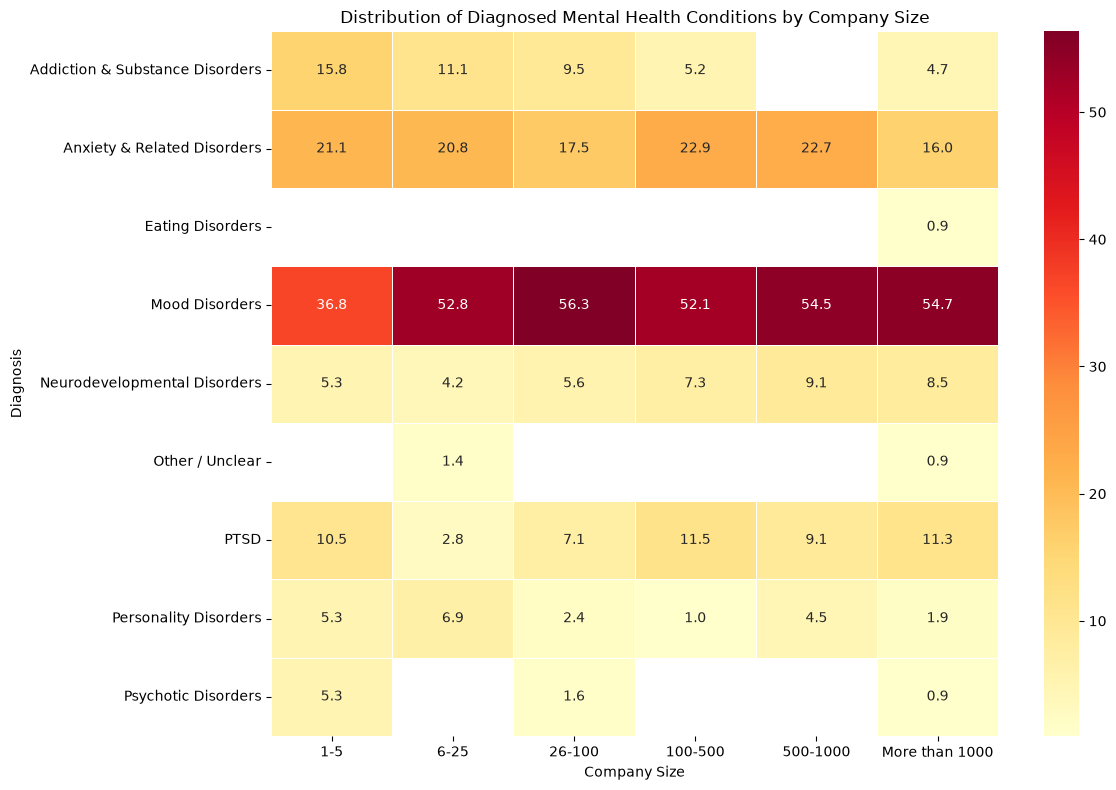

In [ ]:
# Creating Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Distribution of Diagnosed Mental Health Conditions by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Diagnosis")
plt.tight_layout()
plt.show()




##### *The heatmap shows differences in the distribution of reported mental health conditions across company-size groups.*

##### *The percentages should be interpreted within each company-size group rather than as percentages of the entire dataset. Differences between groups may indicate an association between company size and the distribution of reported mental health conditions.*

##### *However, these results do not establish that company size causes differences in mental health outcomes.*

####  **What mental health condition categories are most frequently reported among respondents who provided a usable diagnosis?**

In [ ]:
diagnosis_counts = survey[survey['Diagnosis'] != 'Unknown']['Diagnosis'].value_counts()

Dc = diagnosis_counts.to_frame()
print (Dc)


                                 count
Diagnosis                             
Mood Disorders                     301
Anxiety & Related Disorders        107
PTSD                                45
Addiction & Substance Disorders     41
Neurodevelopmental Disorders        36
Personality Disorders               20
Psychotic Disorders                  6
Other / Unclear                      4
Eating Disorders                     1
Dissociative Disorders               1


<function matplotlib.pyplot.show(close=None, block=None)>

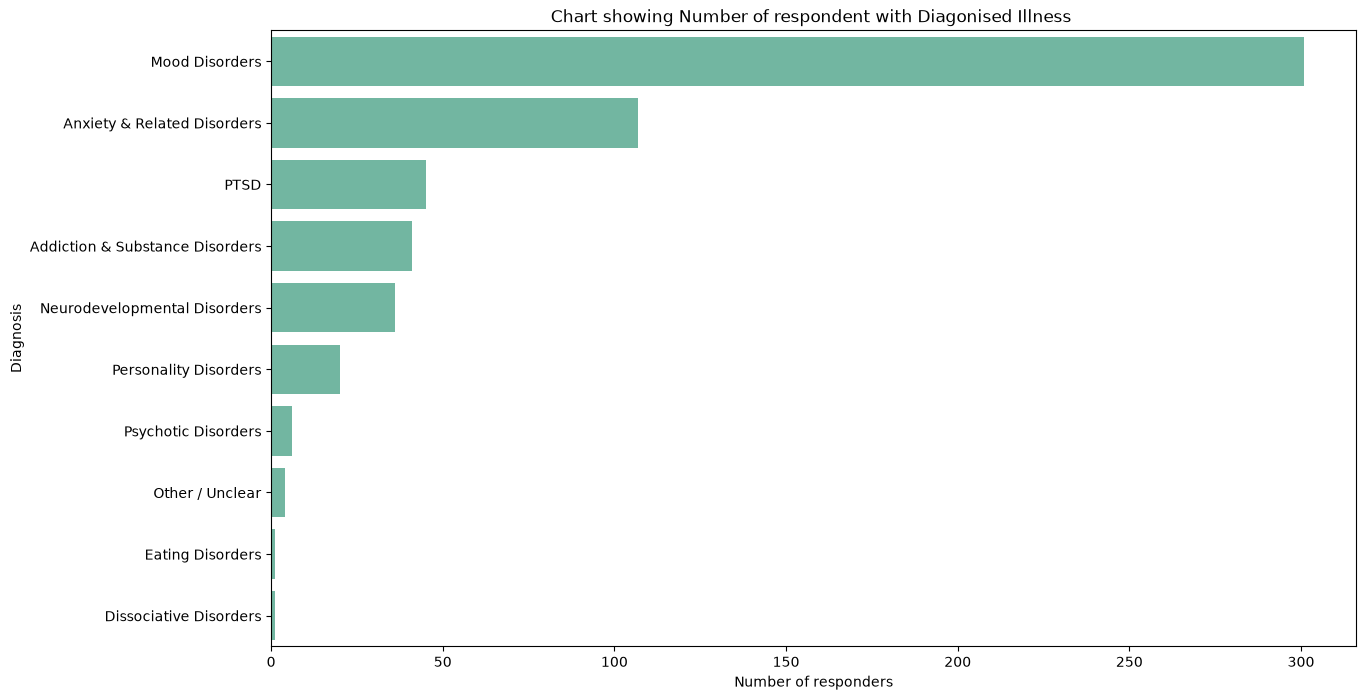

In [ ]:
# Plot a Barplot
plt.figure(figsize=(14, 8))
sns.barplot(data= Dc  , y = 'Diagnosis' , x = 'count'  )


plt.xlabel('Number of responders')
plt.ylabel('Diagnosis')

plt.title ('Chart showing Number of respondent with Diagonised Illness ')

plt.show


Distribution of Mental Health Conditions
- Mood Disorders had the highest number of respondents, with 301 cases.
- Anxiety & Related Disorders had 107 cases, making it the second most frequently reported condition.
- PTSD had 45 cases, making it the least frequently reported among the three conditions.
- The distribution shows that some mental health conditions were reported substantially more frequently than others.
- These differences in frequency should be considered when interpreting subsequent analyses, as estimates based on smaller groups may be less stable.

#### **Prevalence rate  and Confidence Interval of 3 mental Illness** 
 1. Mood Disorder
 2. Anxiety and Related Disorders
 3. PTSD

##### *Formula for calculating Prevalence is coined from number of people diagonised with the condition divided by the sum Population of diagonsed respondent .*
###### $$ \text{Prevalence Rate} =\frac{\text{Number of people with the condition}}{\text{Total number of people in the relevant population}}\times 100 $$

##### *Calculating Confidence Intervals For each prevalence rate, computing the confidence interval (CI). A commonly used CI is the 95% confidence interval, which can be calculated using the formula for the standard error (SE):*


 ###### $$ SE =\sqrt{\frac{p(100-p)}{n}} $$

 ###### where p = Prevalence rate 
 ###### where n = population size 


In [ ]:
# Calculate the Main Denominator to be used for each.
# since Dc was already define , we just calculate the sum of the top 3 as denominator . 
Denominators = Dc[0:3].sum()
Denominator = Denominators.iloc[0]
print (Denominator)



453


##### Prevalence rate and Confidence Interval of Mood Disorder

In [ ]:
# Find Numerator for mood disorder (total count of respondent diagonised with Mood disorder)
md = survey[survey['Diagnosis'] == 'Mood Disorders']['Diagnosis'].value_counts()
Numerator_md = md.iloc[0]


Prevalence_rate_md = (Numerator_md / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate_md)


SE_md = np.sqrt(
    (Prevalence_rate_md * (100 - Prevalence_rate_md)) / Denominator
)

CI_Lower_md = Prevalence_rate_md - (1.96 * SE_md)

CI_Upper_md = Prevalence_rate_md + (1.96 * SE_md)

print("Mood Disorders")
print("SE:", SE_md)
print("95% CI Lower:", CI_Lower_md)
print("95% CI Upper:", CI_Upper_md)

Prevalence_rate : 66.44591611479028
Mood Disorders
SE: 2.2184913450367185
95% CI Lower: 62.09767307851831
95% CI Upper: 70.79415915106225


##### Prevalence rate of Anxiety & Related Disorders

In [ ]:
# Find Numerator for Anxiety and Related Disorders (total count of respondent diagonised with Anxiety and Related Disorders)

ad = survey[survey['Diagnosis'] == 'Anxiety & Related Disorders']['Diagnosis'].value_counts()
Numerator_ad = ad.iloc[0] 


Prevalence_rate_AD = (Numerator_ad / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate_AD)


SE_ad = np.sqrt(
    (Prevalence_rate_AD * (100 - Prevalence_rate_AD)) / Denominator
)

CI_Lower_ad = Prevalence_rate_AD - (1.96 * SE_ad)

CI_Upper_ad = Prevalence_rate_AD + (1.96 * SE_ad)

print("Anxiety & Related Disorders")
print("SE:", SE_ad)
print("95% CI Lower:", CI_Lower_ad)
print("95% CI Upper:", CI_Upper_ad)

Prevalence_rate : 23.62030905077263
Anxiety & Related Disorders
SE: 1.9956419988788814
95% CI Lower: 19.70885073297002
95% CI Upper: 27.531767368575238


##### Prevalence rate of PTSD

In [ ]:
# Find Numerator for PTSD (total count of respondent diagonised with PTSD)

PTsd = survey[survey['Diagnosis'] == 'PTSD']['Diagnosis'].value_counts()
Numerator_PTsd = PTsd.iloc[0] 


Prevalence_rate_for_PTSD = (Numerator_PTsd / Denominator )*100
print("Prevalence_rate :" , Prevalence_rate_for_PTSD)


SE_ptsd = np.sqrt(
    (Prevalence_rate_for_PTSD * (100 - Prevalence_rate_for_PTSD)) / Denominator
)

CI_Lower_ptsd = Prevalence_rate_for_PTSD - (1.96 * SE_ptsd)

CI_Upper_ptsd = Prevalence_rate_for_PTSD + (1.96 * SE_ptsd)

print("PTSD")
print("SE:", SE_ptsd)
print("95% CI Lower:", CI_Lower_ptsd)
print("95% CI Upper:", CI_Upper_ptsd)

Prevalence_rate : 9.933774834437086
PTSD
SE: 1.4053646828469137
95% CI Lower: 7.179260056057135
95% CI Upper: 12.688289612817037


In [ ]:
diag_names = ["Mood Disorders", "Anxiety & Related Disorders", "PTSD"]

denominator = Dc.loc[diag_names, "count"].sum()

rows = []
for illness in diag_names:
    count = Dc.loc[illness, "count"]
    prevalence_rate = (count / denominator) * 100
    se = np.sqrt((prevalence_rate * (100 - prevalence_rate)) / denominator)
    ci_lower = prevalence_rate - (1.96 * se)
    ci_upper = prevalence_rate + (1.96 * se)

    rows.append({
        "Mental_Illness": illness,
        "prevalence_rate": prevalence_rate,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper
    })

illness_prevalence = pd.DataFrame(rows)
illness_prevalence

illness_prevalence

,Mental_Illness,prevalence_rate,CI_Lower,CI_Upper
0,Mood Disorders,66.445916,62.097673,70.794159
1,Anxiety & Related Disorders,23.620309,19.708851,27.531767
2,PTSD,9.933775,7.179260,12.688290


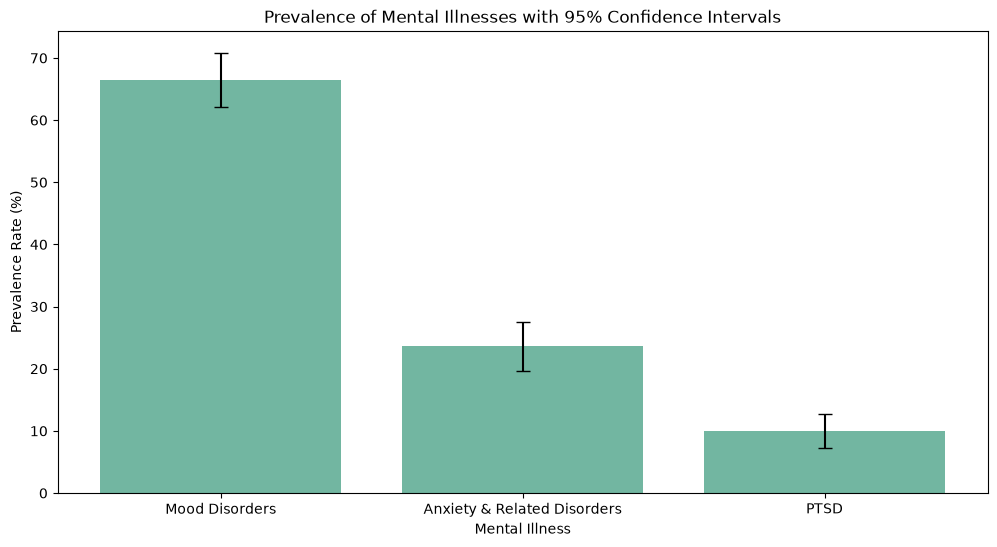

In [ ]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x="Mental_Illness",
    y="prevalence_rate",
    data=illness_prevalence
)

plt.errorbar(
    x=range(len(illness_prevalence)),
    y=illness_prevalence["prevalence_rate"].to_numpy(),
    yerr=[
        illness_prevalence["prevalence_rate"].to_numpy()
        - illness_prevalence["CI_Lower"].to_numpy(),
        illness_prevalence["CI_Upper"].to_numpy()
        - illness_prevalence["prevalence_rate"].to_numpy()
    ],
    fmt="none",
    ecolor = "black",
    capsize=5
)

ax.set_title("Prevalence of Mental Illnesses with 95% Confidence Intervals")
ax.set_xlabel("Mental Illness")
ax.set_ylabel("Prevalence Rate (%)")

plt.show()

##### Prevalence of Mental Illnesses and 95% Confidence Intervals
The prevalence of the three mental illnesses was calculated among the **453 respondents with a known diagnosis**. Each prevalence rate was calculated as the proportion of respondents diagnosed with each mental illness among those with a known diagnosis. A **95% confidence interval using the normal approximation** was then calculated for each prevalence estimate.
| Mental Illness | Number Diagnosed | Prevalence | 95% Confidence Interval |
|---|---:|---:|---:|
| Mood Disorders | 301 | 66.45% | 62.10% – 70.79% |
| Anxiety & Related Disorders | 107 | 23.62% | 19.71% – 27.53% |
| PTSD | 45 | 9.93% | 7.18% – 12.69% |

##### **Interpretation**
Mood Disorders had the highest prevalence at **66.45%**, followed by Anxiety & Related Disorders at **23.62%** and PTSD at **9.93%**. The 95% confidence intervals indicate the plausible range of population prevalence estimates, with narrower intervals representing greater precision. Overall, the results show substantial differences in prevalence across the three conditions, with Mood Disorders affecting approximately two-thirds of respondents with a known diagnosis.
##### **Figure Interpretation**
The graph supports these findings, showing Mood Disorders as the most prevalent condition, followed by Anxiety & Related Disorders and PTSD. The error bars represent the **95% confidence intervals** for each prevalence estimate.



#### **Suggestions for Improvement**
- Include more mental health conditions and demographic variables for a broader analysis.
- Use a larger or more representative sample to improve the reliability of the findings.
- Investigate relationships between mental health and factors such as age, gender, occupation, and work mode.
- Use additional statistical tests to determine whether observed differences are statistically significant.
- Consider using alternative confidence interval methods, such as the Wilson interval, for prevalence estimates.

### **Final Conclusion**

- The analysis provided an overview of **mental health conditions and their distribution among respondents**.
- Data cleaning and categorisation improved the **consistency and reliability** of the dataset for analysis.
- **Mood Disorders** were the most frequently reported condition, followed by **Anxiety & Related Disorders** and **PTSD**.
- The prevalence analysis showed substantial differences between the three conditions, with Mood Disorders accounting for the largest proportion of reported diagnoses.
- Missing values, inconsistent responses, and outliers were identified and considered during the analysis.
- Overall, the findings highlight the **importance of mental health in the workplace** and demonstrate how data analysis can be used to identify patterns and differences in mental health outcomes.